# The Lakehouse Architecture (Iceberg & Delta)

A **data lake** stores files (Parquet) cheaply in object storage, but files alone have no transactions: a reader can
see half-written data, updates mean rewriting files by hand, and nobody knows which files form "the table".
A **lakehouse** adds an **open table format** on top of the files: a metadata layer that gives ACID transactions,
schema enforcement, time travel and efficient updates, while the data stays open Parquet that many engines can read.
The two leading formats are **Delta Lake** and **Apache Iceberg**.

**After this lesson you can:**

1. Explain how a table format turns Parquet files in object storage into a transactional table.
2. Write, append, update, delete and merge a Delta table in S3-compatible storage with `deltalake` (delta-rs).
3. Use time travel, schema enforcement and schema evolution.
4. Measure the small-files problem and fix it with compaction; use Iceberg hidden partitioning for file pruning.

**Data:** NYC taxi trips, January 2024.
**Services:** RustFS (S3-compatible object storage, Apache-2.0): `docker compose -f docker/compose.yml --profile lakehouse up -d rustfs`
(console on http://localhost:9001, user `course`, password `course-password`).

In [1]:
import json
import sys
import time
from pathlib import Path

import boto3
import matplotlib.pyplot as plt
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
from deltalake import DeltaTable, write_deltalake

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: pinned datasets and Docker services

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
datasets.ensure_service("lakehouse", "rustfs")
S3 = {"endpoint_url": "http://localhost:9000", "aws_access_key_id": "course", "aws_secret_access_key": "course-password"}
s3 = boto3.client("s3", region_name="us-east-1", **S3)
BUCKET = "lakehouse"
if BUCKET in [b["Name"] for b in s3.list_buckets()["Buckets"]]:            # clean start on every run
    for page in s3.get_paginator("list_objects_v2").paginate(Bucket=BUCKET, Prefix="lesson04/"):
        for obj in page.get("Contents", []):
            s3.delete_object(Bucket=BUCKET, Key=obj["Key"])
else:
    s3.create_bucket(Bucket=BUCKET)

STORAGE = {"AWS_ENDPOINT_URL": "http://localhost:9000", "AWS_ACCESS_KEY_ID": "course",
           "AWS_SECRET_ACCESS_KEY": "course-password", "AWS_REGION": "us-east-1", "AWS_ALLOW_HTTP": "true",
           "AWS_S3_ALLOW_UNSAFE_RENAME": "true"}   # single writer in this lesson; production uses a lock or conditional writes
DELTA = f"s3://{BUCKET}/lesson04/delta/trips"

raw = pd.read_parquet(datasets.taxi("2024-01"), columns=["tpep_pickup_datetime", "tpep_dropoff_datetime", "PULocationID",
                                                         "DOLocationID", "trip_distance", "fare_amount", "total_amount"])
raw = raw[(raw.tpep_pickup_datetime >= "2024-01-01") & (raw.tpep_pickup_datetime < "2024-01-15")].reset_index(drop=True)
raw["trip_id"] = raw.index.astype("int64")
raw["pickup_date"] = raw.tpep_pickup_datetime.dt.date.astype(str)
for col in ["tpep_pickup_datetime", "tpep_dropoff_datetime"]:   # Iceberg stores microseconds, not nanoseconds
    raw[col] = raw[col].dt.tz_localize("UTC").astype("datetime64[us, UTC]")
day = {d: g.reset_index(drop=True) for d, g in raw.groupby("pickup_date")}
print(f"{len(raw):,} trips over {len(day)} days; first day {min(day)}: {len(day[min(day)]):,} trips")

def objects(prefix: str) -> pd.DataFrame:
    rows = [{"key": o["Key"].removeprefix(prefix), "bytes": o["Size"]}
            for page in s3.get_paginator("list_objects_v2").paginate(Bucket=BUCKET, Prefix=prefix)
            for o in page.get("Contents", [])]
    return pd.DataFrame(rows, columns=["key", "bytes"])

1,286,537 trips over 14 days; first day 2024-01-01: 81,013 trips


## 1. A Table = Data Files + a Transaction Log

`write_deltalake` writes Parquet files **and** a JSON commit into `_delta_log/`. A commit lists the files it
**adds** and **removes**, with statistics (min/max per column). Readers build the table from the log, never by
listing the folder, so a half-written file that is not in the log is invisible.

In [2]:
days = sorted(day)
write_deltalake(DELTA, day[days[0]], partition_by=["pickup_date"], storage_options=STORAGE)
dt = DeltaTable(DELTA, storage_options=STORAGE)
print("version:", dt.version(), "| files:", len(dt.file_uris()))
log = objects("lesson04/delta/trips/")
print(log.to_string(index=False))

commit = s3.get_object(Bucket=BUCKET, Key="lesson04/delta/trips/_delta_log/00000000000000000000.json")["Body"].read().decode()
actions = [json.loads(l) for l in commit.splitlines()]
print("\nactions in commit 0:", [list(a)[0] for a in actions])
add = next(a["add"] for a in actions if "add" in a)
stats = json.loads(add["stats"])
print("add.path:", add["path"])
print("add.stats.numRecords:", stats["numRecords"], "| min fare:", stats["minValues"]["fare_amount"],
      "| max fare:", stats["maxValues"]["fare_amount"])

version: 0 | files: 1
                                                                                       key   bytes
                                                      _delta_log/00000000000000000000.json    2450
pickup_date=2024-01-01/part-00000-703440d5-8fee-42b8-bc77-d15d494f75cf-c000.snappy.parquet 1981760

actions in commit 0: ['commitInfo', 'protocol', 'metaData', 'add']
add.path: pickup_date=2024-01-01/part-00000-703440d5-8fee-42b8-bc77-d15d494f75cf-c000.snappy.parquet
add.stats.numRecords: 81013 | min fare: -404.1 | max fare: 820.0


## 2. Appends Are Atomic Transactions

Each append creates a new table **version**. The cell appends the remaining 13 days one by one, then shows the
history. Any reader always sees a complete version: before or after a commit, never in between.

In [3]:
for d in days[1:]:
    write_deltalake(DELTA, day[d], mode="append", partition_by=["pickup_date"], storage_options=STORAGE)
dt = DeltaTable(DELTA, storage_options=STORAGE)
hist = pd.DataFrame(dt.history())[["version", "operation", "timestamp"]].sort_values("version")
print(hist.tail(4).to_string(index=False))
print("version:", dt.version(), "| files:", len(dt.file_uris()),
      "| rows:", dt.to_pyarrow_dataset().count_rows())

 version operation     timestamp
      10     WRITE 1794935495811
      11     WRITE 1794935495911
      12     WRITE 1794935496005
      13     WRITE 1794935496103
version: 13 | files: 14 | rows: 1286537


## 3. Delete, Update and Merge

Plain Parquet cannot change a row; a table format rewrites only the affected files and records the swap in one
commit. The cell removes invalid trips (negative totals) and runs a **MERGE** (upsert) with corrected records from a
"late delivery": matching trips are updated, new trips are inserted.

In [4]:
before = dt.to_pyarrow_dataset().count_rows()
m_del = dt.delete("total_amount < 0")

corrections = raw.sample(500, random_state=1).copy()
corrections["total_amount"] = corrections.total_amount + 1.0               # e.g. a forgotten congestion fee
new = day[days[-1]].head(200).copy()
new["trip_id"] = new.trip_id + 10_000_000                                   # trips the lake has not seen yet
source = pd.concat([corrections, new])
m_merge = (dt.merge(source=source, predicate="t.trip_id = s.trip_id AND t.pickup_date = s.pickup_date",
                    source_alias="s", target_alias="t")
             .when_matched_update(updates={"total_amount": "s.total_amount"})
             .when_not_matched_insert_all()
             .execute())
dt = DeltaTable(DELTA, storage_options=STORAGE)
print(f"rows before: {before:,} | deleted: {m_del['num_deleted_rows']:,} | merge updated: "
      f"{m_merge['num_target_rows_updated']} inserted: {m_merge['num_target_rows_inserted']} | rows now: "
      f"{dt.to_pyarrow_dataset().count_rows():,}")
print("files rewritten by the merge:", m_merge["num_target_files_added"], "of", len(dt.file_uris()))

rows before: 1,286,537 | deleted: 16,090 | merge updated: 495 inserted: 205 | rows now: 1,270,652
files rewritten by the merge: 14 of 14


## 4. Time Travel

Old versions stay readable until their files are vacuumed: reproduce last week's report, debug a bad load,
or roll back.

In [5]:
v_after_appends = len(days) - 1
for v in [0, v_after_appends, dt.version()]:
    t = DeltaTable(DELTA, storage_options=STORAGE, version=v).to_pyarrow_table(columns=["total_amount"])
    print(f"version {v:>2}: {t.num_rows:>9,} rows, revenue {pc.sum(t['total_amount']).as_py():>14,.2f}")

version  0:    81,013 rows, revenue   2,442,843.25


version 13: 1,286,537 rows, revenue  34,954,915.55
version 15: 1,270,652 rows, revenue  35,371,641.00


## 5. Schema Enforcement and Evolution

A table format **rejects** writes whose schema does not match (no silent garbage), and allows **explicit** evolution.

In [6]:
extra = day[days[-1]].head(10).copy()
extra["payment_note"] = "card"                    # a column the table does not have
try:
    write_deltalake(DELTA, extra, mode="append", partition_by=["pickup_date"], storage_options=STORAGE)
except Exception as e:
    print("rejected:", type(e).__name__, str(e).splitlines()[0][:110])
write_deltalake(DELTA, extra, mode="append", partition_by=["pickup_date"], schema_mode="merge", storage_options=STORAGE)
dt = DeltaTable(DELTA, storage_options=STORAGE)
print("after schema_mode='merge':", [f.name for f in dt.schema().fields][-3:])

rejected: SchemaMismatchError Cannot cast schema, number of fields does not match: 10 vs 9
after schema_mode='merge': ['trip_id', 'pickup_date', 'payment_note']


## 6. The Small-Files Problem and Compaction

Streaming and frequent appends create many small files. Every file costs a request to object storage, so queries
slow down. **Compaction** (`OPTIMIZE`) rewrites small files into large ones in a new commit; **Z-ordering** also
sorts the data so that file statistics can skip more files. The cell simulates 300 micro-batches, then compacts.

files: 300 -> 1 | query (zone 132): 389 ms -> 7 ms


vacuum removed 300 old data files | data files left: 1 | log objects (commits + checkpoints): 307


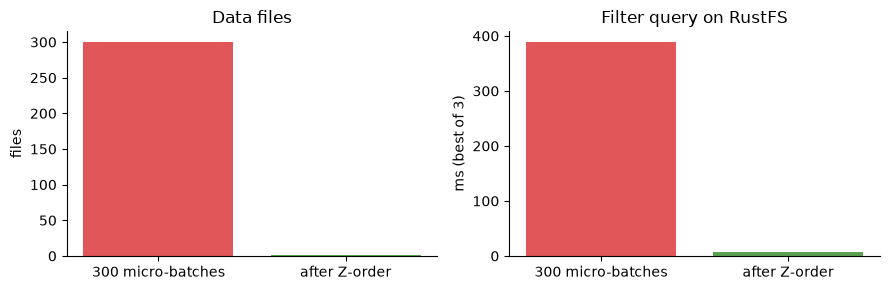

In [7]:
SMALL = f"s3://{BUCKET}/lesson04/delta/small"
batches = [day[days[0]].iloc[i::300] for i in range(300)]
for i, b in enumerate(batches):
    write_deltalake(SMALL, b, mode="append" if i else "error", storage_options=STORAGE)
small = DeltaTable(SMALL, storage_options=STORAGE)

def timed_query(t: DeltaTable) -> float:
    best = 1e9
    for _ in range(3):
        t0 = time.perf_counter()
        t.to_pyarrow_dataset().to_table(filter=pc.field("PULocationID") == 132, columns=["total_amount"])
        best = min(best, time.perf_counter() - t0)
    return best

files_before, q_before = len(small.file_uris()), timed_query(small)
small.optimize.z_order(["PULocationID"])
small = DeltaTable(SMALL, storage_options=STORAGE)
files_after, q_after = len(small.file_uris()), timed_query(small)
print(f"files: {files_before} -> {files_after} | query (zone 132): {q_before*1000:.0f} ms -> {q_after*1000:.0f} ms")
removed = small.vacuum(retention_hours=0, enforce_retention_duration=False, dry_run=False)
left = objects("lesson04/delta/small/")
data_left = [k for k in left.key if "_delta_log/" not in k]
print(f"vacuum removed {len(removed)} old data files | data files left: {len(data_left)} | "
      f"log objects (commits + checkpoints): {len(left) - len(data_left)}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].bar(["300 micro-batches", "after Z-order"], [files_before, files_after], color=["#E15759", "#59A14F"])
ax[0].set(title="Data files", ylabel="files")
ax[1].bar(["300 micro-batches", "after Z-order"], [q_before * 1000, q_after * 1000], color=["#E15759", "#59A14F"])
ax[1].set(title="Filter query on RustFS", ylabel="ms (best of 3)")
plt.tight_layout(); plt.show()

*Insight: Small files are the most common lakehouse performance problem. Schedule compaction for tables written by streams, and vacuum old files after the time-travel window you need.*

## 7. Apache Iceberg: the Same Ideas, a Different Metadata Design

Iceberg keeps a tree of metadata: a **metadata.json** (schema, partition spec, snapshots) → **manifest lists** →
**manifests** (data files with column statistics). Two features stand out:

- **Hidden partitioning:** partition by a transform such as `day(pickup)`; queries filter on the timestamp and
  Iceberg prunes files, without a separate `pickup_date` column.
- **Partition and schema evolution** without rewriting data.

Here PyIceberg uses a local SQL catalog (SQLite) with the data in RustFS; Lesson 05 uses a shared REST catalog.

In [8]:
import tempfile
from pyiceberg.catalog.sql import SqlCatalog
from pyiceberg.partitioning import PartitionField, PartitionSpec
from pyiceberg.transforms import DayTransform
from pyiceberg.expressions import And, GreaterThanOrEqual, LessThan

catalog = SqlCatalog("local", uri=f"sqlite:///{tempfile.mkdtemp()}/catalog.db",
                     warehouse=f"s3://{BUCKET}/lesson04/iceberg", **{"s3.endpoint": "http://localhost:9000",
                     "s3.access-key-id": "course", "s3.secret-access-key": "course-password", "s3.region": "us-east-1"})
catalog.create_namespace_if_not_exists("taxi")
arrow = pa.Table.from_pandas(raw.drop(columns=["pickup_date"]), preserve_index=False)
schema = catalog.create_table("taxi.tmp_schema", schema=arrow.schema).schema()   # Iceberg schema with field IDs
catalog.drop_table("taxi.tmp_schema")
pickup_id = schema.find_field("tpep_pickup_datetime").field_id
spec = PartitionSpec(PartitionField(source_id=pickup_id, field_id=1000, transform=DayTransform(), name="pickup_day"))
trips = catalog.create_table("taxi.trips", schema=schema, partition_spec=spec)
for d in days:                                     # one snapshot per daily load
    trips.append(pa.Table.from_pandas(day[d].drop(columns=["pickup_date"]), schema=arrow.schema, preserve_index=False))
print("snapshots:", len(trips.snapshots()), "| rows:", trips.scan().count())

all_files = len(list(trips.scan().plan_files()))
one_day = trips.scan(row_filter=And(GreaterThanOrEqual("tpep_pickup_datetime", "2024-01-07T00:00:00+00:00"),
                                    LessThan("tpep_pickup_datetime", "2024-01-08T00:00:00+00:00")))
print(f"files planned: full scan {all_files}, filter on one day {len(list(one_day.plan_files()))} (hidden partition pruning)")
print("rows on 2024-01-07:", one_day.count())

first_snap = trips.snapshots()[0].snapshot_id
print("time travel to the first snapshot:", trips.scan(snapshot_id=first_snap).count(), "rows")
with trips.update_schema() as u:
    u.rename_column("total_amount", "total_usd")
print("renamed without rewriting data:", [f.name for f in trips.schema().fields][-3:])

snapshots: 14 | rows: 1286537
files planned: full scan 14, filter on one day 1 (hidden partition pruning)
rows on 2024-01-07: 67543
time travel to the first snapshot: 81013 rows


renamed without rewriting data: ['fare_amount', 'total_usd', 'trip_id']


| | Delta Lake | Apache Iceberg |
| :--- | :--- | :--- |
| metadata | ordered JSON log + Parquet checkpoints | metadata.json → manifest lists → manifests |
| partitioning | explicit columns (plus liquid clustering) | hidden transforms, partition evolution |
| catalogs | file path, Unity Catalog | REST catalog spec (Polaris, Nessie, Glue, Unity, ...) |
| strongest ecosystem | Spark/Databricks, delta-rs | Spark, Trino, Flink, Snowflake, DuckDB, PyIceberg |

Both converge: Delta UniForm writes Iceberg metadata too, and most engines read both.

*Insight: The table format, not the engine, owns the table. Keep data in an open format and you can query the same table from Spark, DuckDB, Trino or a warehouse, and switch engines later.*

## Real-World Use Case or Analogy

A table format is like the **index card catalogue of a library**: the books (Parquet files) stay on the shelves,
but the catalogue decides which books belong to the collection right now, records every change, and remembers what
the collection looked like last year. Without it you only have a room full of books.

Netflix created Iceberg for its petabyte-scale data lake on S3; Databricks created Delta Lake. Today, companies
store one copy of their data in Iceberg or Delta and let analysts (SQL), data scientists (Python) and streaming
jobs (Flink) work on the same tables.